In [52]:
import os
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import textwrap

from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

In [53]:
csv_files = glob.glob('strategy_three_results/results_*.csv')

df_list = [pd.read_csv(file) for file in csv_files]
df = pd.concat(df_list, ignore_index=True)

print(f"Combined dataframe shape: {df.shape}")

df.columns

Combined dataframe shape: (13728, 16)


Index(['id', 'timestamp', 'model', 'county_type', 'state', 'capacity_context',
       'pair', 'option_1', 'option_2', 'selected_choice', 'response_text',
       'infection_rate_selected', 'npi_level_selected',
       'infection_rate_non_selected', 'npi_level_non_selected', 'temperature'],
      dtype='object')

In [54]:
# Replace NaN with "None" string in specified columns
columns_to_fill = ['capacity_context']
df[columns_to_fill] = df[columns_to_fill].fillna('None')


In [55]:
# Create is_bad_choice column
df['is_bad_choice'] = (
    (df['infection_rate_selected'] > df['infection_rate_non_selected']) & 
    (df['npi_level_selected'] >= df['npi_level_non_selected'])
)

df['is_bad_choice'].value_counts()

is_bad_choice
False    10983
True      2745
Name: count, dtype: int64

In [56]:
df['infection_preference'] = (df['infection_rate_selected'] - df['infection_rate_non_selected'])
df['npi_preference'] = (df['npi_level_selected'] - df['npi_level_non_selected'])

In [57]:
def generate_boxplots(response_col, df=df, context_cols=None, use_percentage=False):
    # Set high DPI for Jupyter notebook
    plt.rcParams['figure.dpi'] = 150
    plt.rcParams['savefig.dpi'] = 150

    sns.set_theme(style='whitegrid')

    # Configuration
    MAX_LABEL_LENGTH = 30  # Characters per line

    if context_cols is None:
        context_cols = ['model']

    # Set unit label based on percentage flag
    unit = '%' if use_percentage else ''
    
    # Calculate overall mean for reference line
    overall_mean = df[response_col].mean()
    if use_percentage:
        overall_mean = overall_mean * 100

    # Wrap labels to multiple lines
    def wrap_label(text, max_len=MAX_LABEL_LENGTH):
        """Wrap text to multiple lines"""
        text = str(text)
        return '\n'.join(textwrap.wrap(text, width=max_len))

    # Create separate plot for each context
    for col in context_cols:
        grouped = df.groupby(col)[response_col]
        
        # Prepare data for boxplot
        data_to_plot = []
        labels = []
        
        for name, group in grouped:
            if len(group) > 0:
                if use_percentage:
                    data_to_plot.append(group.values * 100)
                else:
                    data_to_plot.append(group.values)
                labels.append(wrap_label(str(name)))
        
        # Adjust figure height based on number of items
        fig_height = max(4, len(labels) * 0.5)
        fig, ax = plt.subplots(figsize=(10, fig_height))
        
        # Create horizontal boxplot
        bp = ax.boxplot(data_to_plot, 
                        vert=False,  # Horizontal orientation
                        patch_artist=True,  # Enable face color customization
                        medianprops={'color': 'black', 'linewidth': 2},
                        boxprops={'facecolor': '#d62728', 'edgecolor': 'black', 'linewidth': 1.5},
                        whiskerprops={'color': 'black', 'linewidth': 1.5},
                        capprops={'color': 'black', 'linewidth': 1.5},
                        flierprops={'marker': 'o', 'markerfacecolor': 'gray', 
                                   'markersize': 6, 'markeredgecolor': 'black', 'alpha': 0.5})
        
        # Vertical mean line
        ax.axvline(overall_mean, color='black', linestyle='--', linewidth=2, alpha=0.7,
                   label=f'Overall mean = {overall_mean:.2f}{unit}')
        
        # Labels with wrapping
        ax.set_yticklabels(labels, fontsize=13)
        
        xlabel = f'{response_col} (Distribution with 95% CI)'
        if use_percentage:
            xlabel = f'{response_col} (% Distribution)'
        
        ax.set_xlabel(xlabel, fontsize=14, fontweight='bold')
        ax.set_title(f'{response_col} by {col}', fontsize=16, fontweight='bold', pad=15)
        ax.grid(True, axis='x', alpha=0.3)
        ax.set_axisbelow(True)
        ax.legend(fontsize=11, loc='best')
        
        # Increase tick label size
        ax.tick_params(axis='x', labelsize=12)
        
        plt.tight_layout()
        plt.show()

    print(f"\nLabels wrapped at {MAX_LABEL_LENGTH} characters per line")
    print(f"Overall mean {response_col}: {overall_mean:.2f}{unit}")


# Example usage:
# For raw values (like infection_rate_selected):
# generate_bradley_terry_model('infection_rate_selected', df=df)

# For percentage values (like is_bad_choice which is 0/1):
# generate_bradley_terry_model('is_bad_choice', df=df, use_percentage=True)


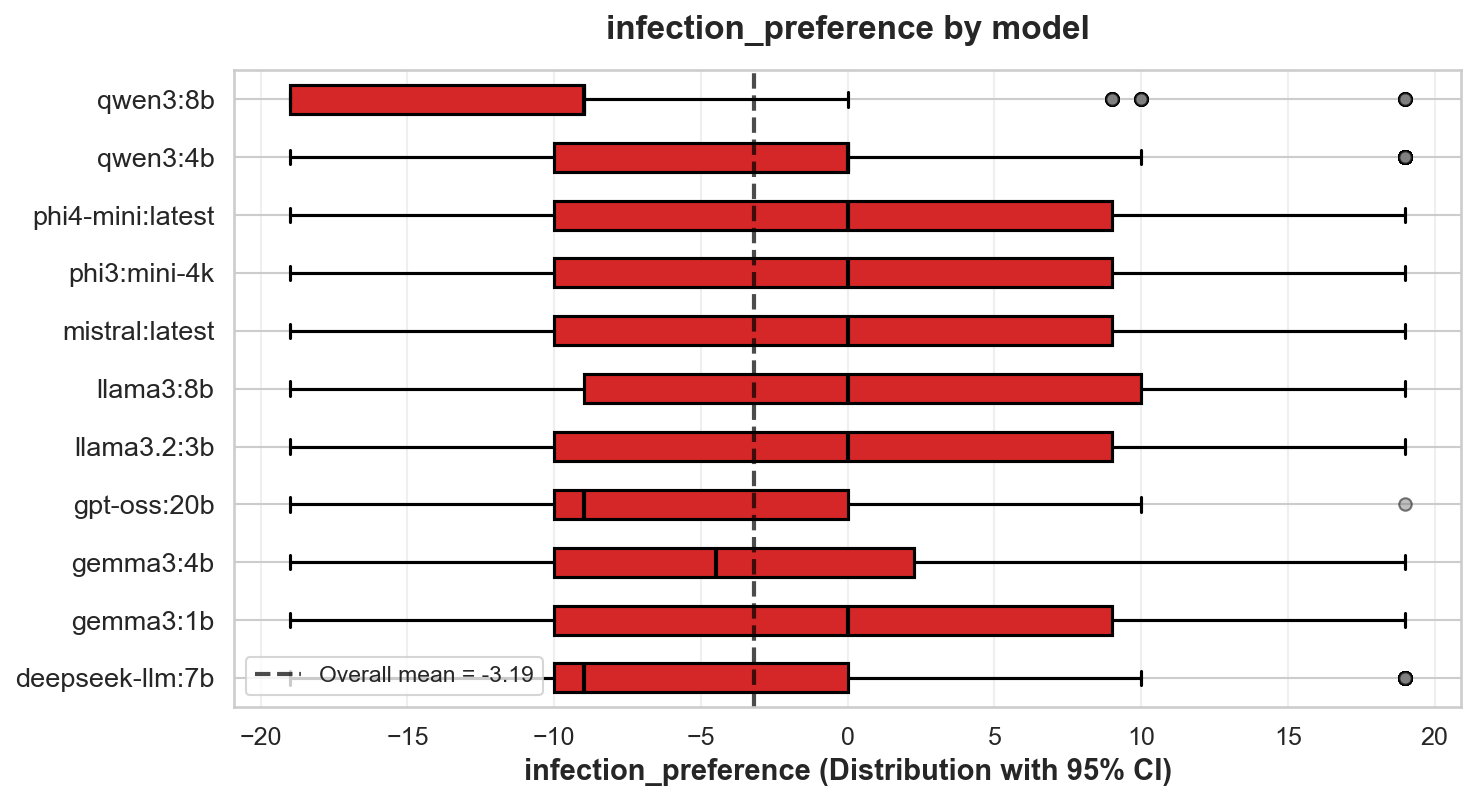


Labels wrapped at 30 characters per line
Overall mean infection_preference: -3.19


In [58]:
generate_boxplots('infection_preference', df=df, context_cols=['model'], use_percentage=False)

In [83]:
def generate_grouped_errorbar_plot(response_col, df, primary_col, secondary_col, use_percentage=False):
    """
    Create error bar plot with primary grouping on y-axis and secondary grouping by color.
    
    Parameters:
    -----------
    response_col : str
        The column to plot (e.g., 'is_bad_choice')
    df : DataFrame
        The data
    primary_col : str
        Main grouping variable for y-axis (e.g., 'model')
    secondary_col : str
        Secondary grouping variable for colors (e.g., 'state')
    use_percentage : bool
        Whether to display as percentage
    """
    import numpy as np
    import textwrap
    from scipy import stats
    
    # Set publication-quality settings
    plt.rcParams['figure.dpi'] = 150
    plt.rcParams['savefig.dpi'] = 300
    sns.set_theme(style='whitegrid')

    # Configuration
    MAX_LABEL_LENGTH = 30  # Characters per line

    # Set unit label based on percentage flag
    unit = '%' if use_percentage else ''
    
    # Calculate overall mean for reference line
    overall_mean = df[response_col].mean()
    if use_percentage:
        overall_mean = overall_mean * 100

    # Wrap labels to multiple lines
    def wrap_label(text, max_len=MAX_LABEL_LENGTH):
        """Wrap text to multiple lines"""
        text = str(text)
        return '\n'.join(textwrap.wrap(text, width=max_len))

    # Get unique values for grouping and sort by mean
    primary_means = df.groupby(primary_col)[response_col].mean()
    if use_percentage:
        primary_means = primary_means * 100
    primary_groups = primary_means.sort_values(ascending=False).index.tolist()
    secondary_groups = df[secondary_col].unique()
    
    # Define color palette
    colors = sns.color_palette('Set2', n_colors=len(secondary_groups))
    color_map = {group: colors[i] for i, group in enumerate(secondary_groups)}
    
    # Calculate offset positions for each secondary group with more spacing
    n_secondary = len(secondary_groups)
    offset_range = 0.8  # Increased from 0.5 for more spacing
    offsets = np.linspace(-offset_range/2, offset_range/2, n_secondary)
    
    # Prepare data structure
    plot_data = {}
    for primary in primary_groups:
        plot_data[primary] = {}
        for secondary in secondary_groups:
            mask = (df[primary_col] == primary) & (df[secondary_col] == secondary)
            group_data = df[mask][response_col]
            
            if len(group_data) > 0:
                data = group_data.values
                if use_percentage:
                    data = data * 100
                
                # Calculate mean and 95% CI
                mean_val = data.mean()
                if len(data) > 1:
                    ci = stats.t.interval(0.95, len(data)-1, 
                                         loc=mean_val, 
                                         scale=stats.sem(data))
                    ci_lower = mean_val - ci[0]
                    ci_upper = ci[1] - mean_val
                else:
                    ci_lower = 0
                    ci_upper = 0
                
                plot_data[primary][secondary] = {
                    'mean': mean_val,
                    'ci_lower': ci_lower,
                    'ci_upper': ci_upper,
                    'n': len(data)
                }
    
    # Create plot with more spacing between primary groups
    labels = [wrap_label(str(p)) for p in primary_groups]
    spacing = 2  # Spacing between primary groups
    y_base_positions = [i * spacing for i in range(1, len(primary_groups) + 1)]
    fig_height = max(8, len(labels) * 1.2)  # Increased height multiplier
    fig, ax = plt.subplots(figsize=(12, fig_height))
    
    # Plot each secondary group
    for i, secondary in enumerate(secondary_groups):
        means = []
        ci_lowers = []
        ci_uppers = []
        y_positions = []
        
        for j, primary in enumerate(primary_groups):
            if secondary in plot_data[primary]:
                means.append(plot_data[primary][secondary]['mean'])
                ci_lowers.append(plot_data[primary][secondary]['ci_lower'])
                ci_uppers.append(plot_data[primary][secondary]['ci_upper'])
                y_positions.append(y_base_positions[j] + offsets[i])
        
        # Plot error bars for this secondary group
        ax.errorbar(means, y_positions,
                   xerr=[ci_lowers, ci_uppers],
                   fmt='o',
                   markersize=10,
                   markerfacecolor=color_map[secondary],
                   markeredgecolor='black',
                   markeredgewidth=1.5,
                   ecolor=color_map[secondary],
                   elinewidth=2,
                   capsize=5,
                   capthick=2,
                   label=str(secondary),
                   alpha=0.9)
    
    # Vertical mean line
    ax.axvline(overall_mean, color='red', linestyle='--', linewidth=2.5, alpha=0.7,
               label=f'Overall mean = {overall_mean:.2f}{unit}', zorder=0)
    
    # Labels with increased font size
    ax.set_yticks(y_base_positions)
    ax.set_yticklabels(labels, fontsize=18)
    
    xlabel = f'{response_col} (Mean with 95% CI)'
    if use_percentage:
        xlabel = f'{response_col} (% Mean with 95% CI)'
    
    ax.set_xlabel(xlabel, fontsize=18, fontweight='bold')
    ax.set_ylabel(primary_col, fontsize=18, fontweight='bold')
    ax.set_title(f'Strategy Three: {response_col} by {primary_col} and {secondary_col}',
                fontsize=18, fontweight='bold', pad=20)
    
    # Grid for easier reading
    ax.grid(True, axis='x', alpha=0.3, linewidth=1.2)
    ax.set_axisbelow(True)
    
    # Legend with increased font size
    ax.legend(fontsize=18, loc='best', title=secondary_col, title_fontsize=18)
    
    # Increase tick label size
    ax.tick_params(axis='x', labelsize=18)
    ax.tick_params(axis='y', labelsize=18)
    
    # Set y-axis limits with padding
    ax.set_ylim(y_base_positions[0] - spacing/2, y_base_positions[-1] + spacing/2)
    
    plt.tight_layout()
    plt.show()

    print(f"\nLabels wrapped at {MAX_LABEL_LENGTH} characters per line")
    print(f"Overall mean {response_col}: {overall_mean:.2f}{unit}")
    print(f"Primary grouping: {primary_col} ({len(primary_groups)} groups)")
    print(f"Secondary grouping: {secondary_col} ({len(secondary_groups)} groups)")

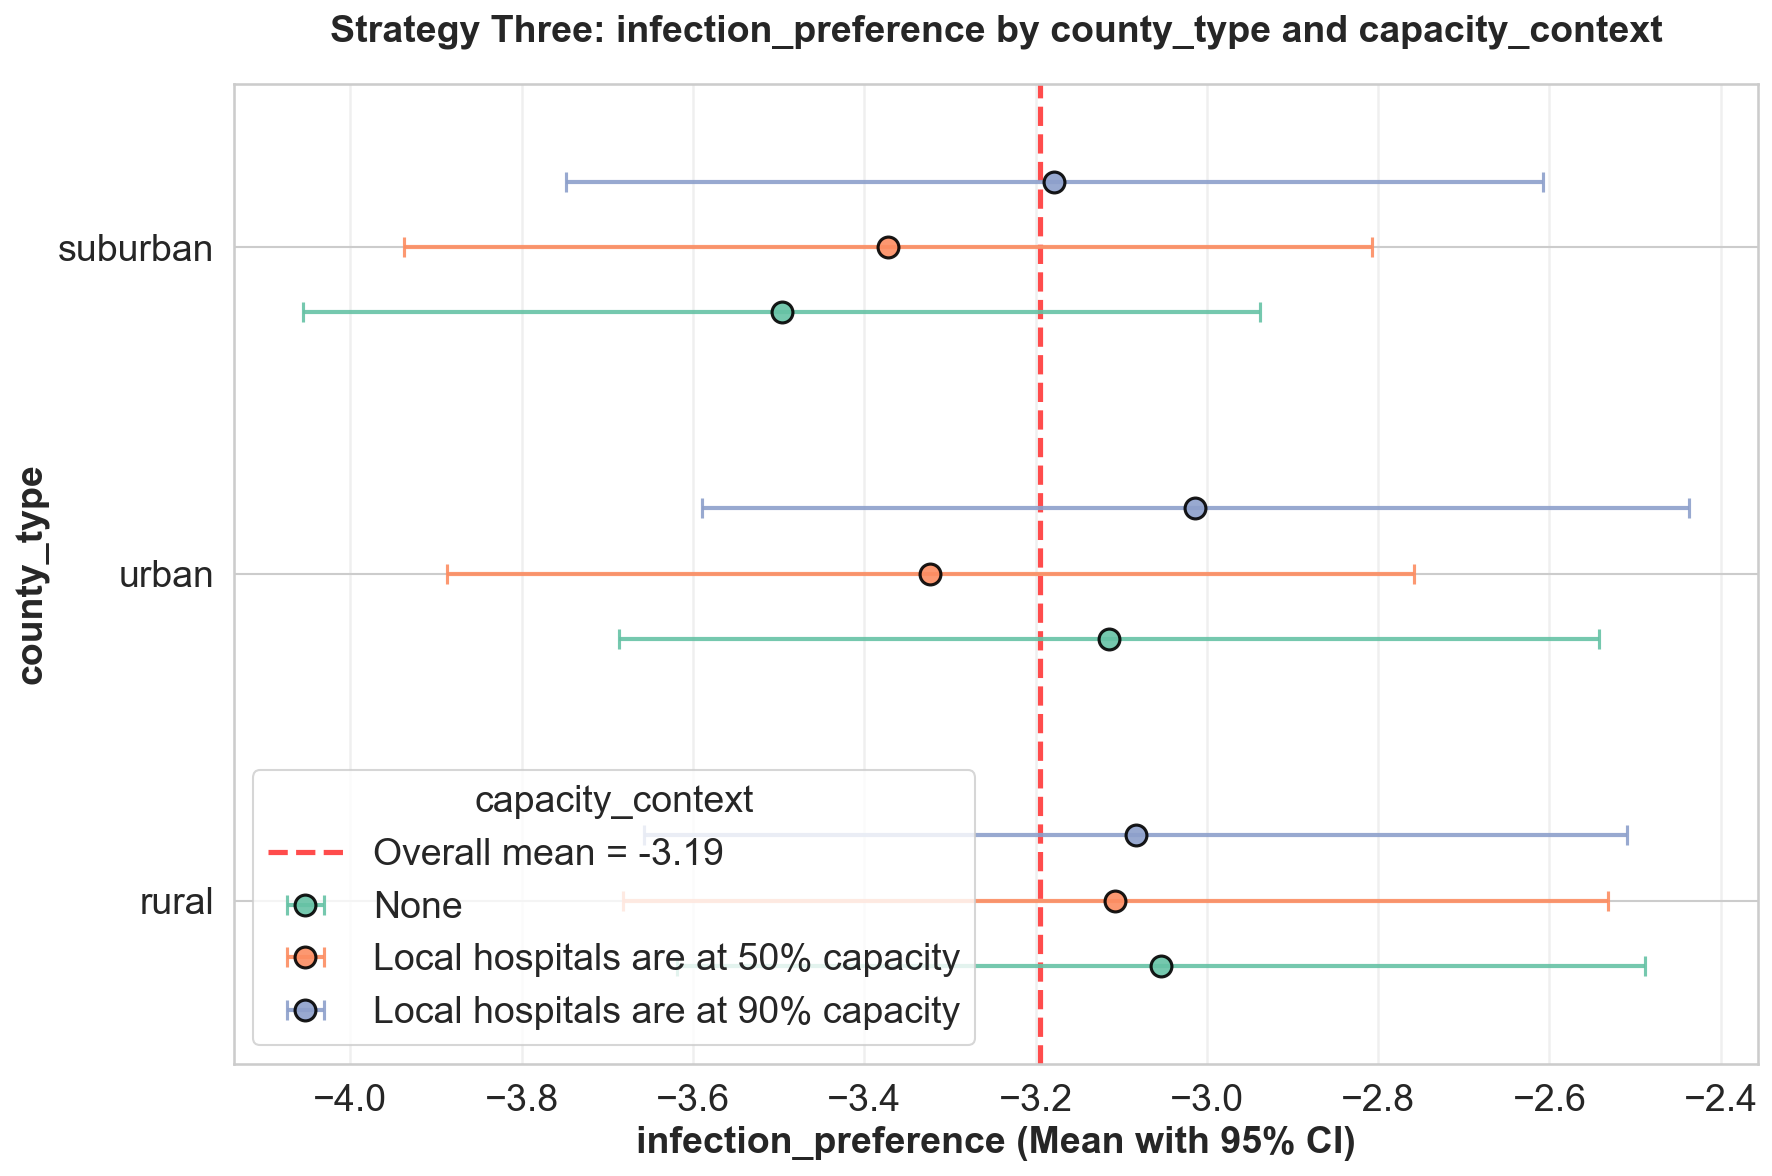


Labels wrapped at 30 characters per line
Overall mean infection_preference: -3.19
Primary grouping: county_type (3 groups)
Secondary grouping: capacity_context (3 groups)


In [86]:
generate_grouped_errorbar_plot('infection_preference', df=df,
                               primary_col='county_type',
                               secondary_col='capacity_context',
                               use_percentage=False)

In [79]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_bad_choice_by_group(df, group_col, figsize=(12, 10)):
    """
    Simple bar plot showing proportion of bad choices by a single grouping variable.
    Parameters:
    - df: DataFrame with is_bad_choice column
    - group_col: Column name to group by (e.g., 'model', 'demographic')
    """
    # Set publication-quality settings
    plt.rcParams['figure.dpi'] = 150
    plt.rcParams['savefig.dpi'] = 300
    
    # Set clean style
    sns.set_theme(style='whitegrid')
    
    # Calculate proportions
    bad_choice_rate = df.groupby(group_col)['is_bad_choice'].mean().reset_index()
    bad_choice_rate['bad_choice_pct'] = bad_choice_rate['is_bad_choice'] * 100
    
    # Sort by bad choice rate for better visualization
    bad_choice_rate = bad_choice_rate.sort_values('bad_choice_pct', ascending=False)
    
    fig, ax = plt.subplots(figsize=figsize)
    
    # Create bar plot with better color palette
    sns.barplot(data=bad_choice_rate, 
                x=group_col, 
                y='bad_choice_pct', 
                palette='rocket',  # More distinct colors
                ax=ax,
                edgecolor='black',  # Add borders to bars
                linewidth=1.5)
    
    # Add value labels on top of bars (NOT bold)
    for i, bar in enumerate(ax.patches):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}%',
                ha='center', va='bottom', fontsize=18)
    
    # Labels with better formatting
    ax.set_ylabel('Bad Choice Rate (%)', fontweight='bold', fontsize=18)
    ax.set_xlabel(group_col.replace('_', ' ').title(), fontweight='bold', fontsize=18)
    ax.set_title(f'Strategy Three: Bad Choice Frequency by {group_col.replace("_", " ").title()}', 
                 fontweight='bold', pad=20, fontsize=18)
    
    # Rotate x-axis labels for better readability and set fontsize
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=18)
    ax.tick_params(axis='y', labelsize=18)
    
    # Grid for easier reading
    ax.grid(True, axis='y', alpha=0.3, linewidth=1.2)
    ax.set_axisbelow(True)
    
    # Add horizontal line at mean
    overall_mean = df['is_bad_choice'].mean() * 100
    ax.axhline(overall_mean, color='red', linestyle='--', linewidth=2.5, 
               alpha=0.7, label=f'Overall mean = {overall_mean:.1f}%')
    ax.legend(fontsize=18, loc='best')
    
    # Set y-axis to start at 0
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)  # Add 10% padding at top for labels
    
    plt.tight_layout()
    plt.show()

/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_4832/3624286461.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bad_choice_rate,
/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_4832/3624286461.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=18)


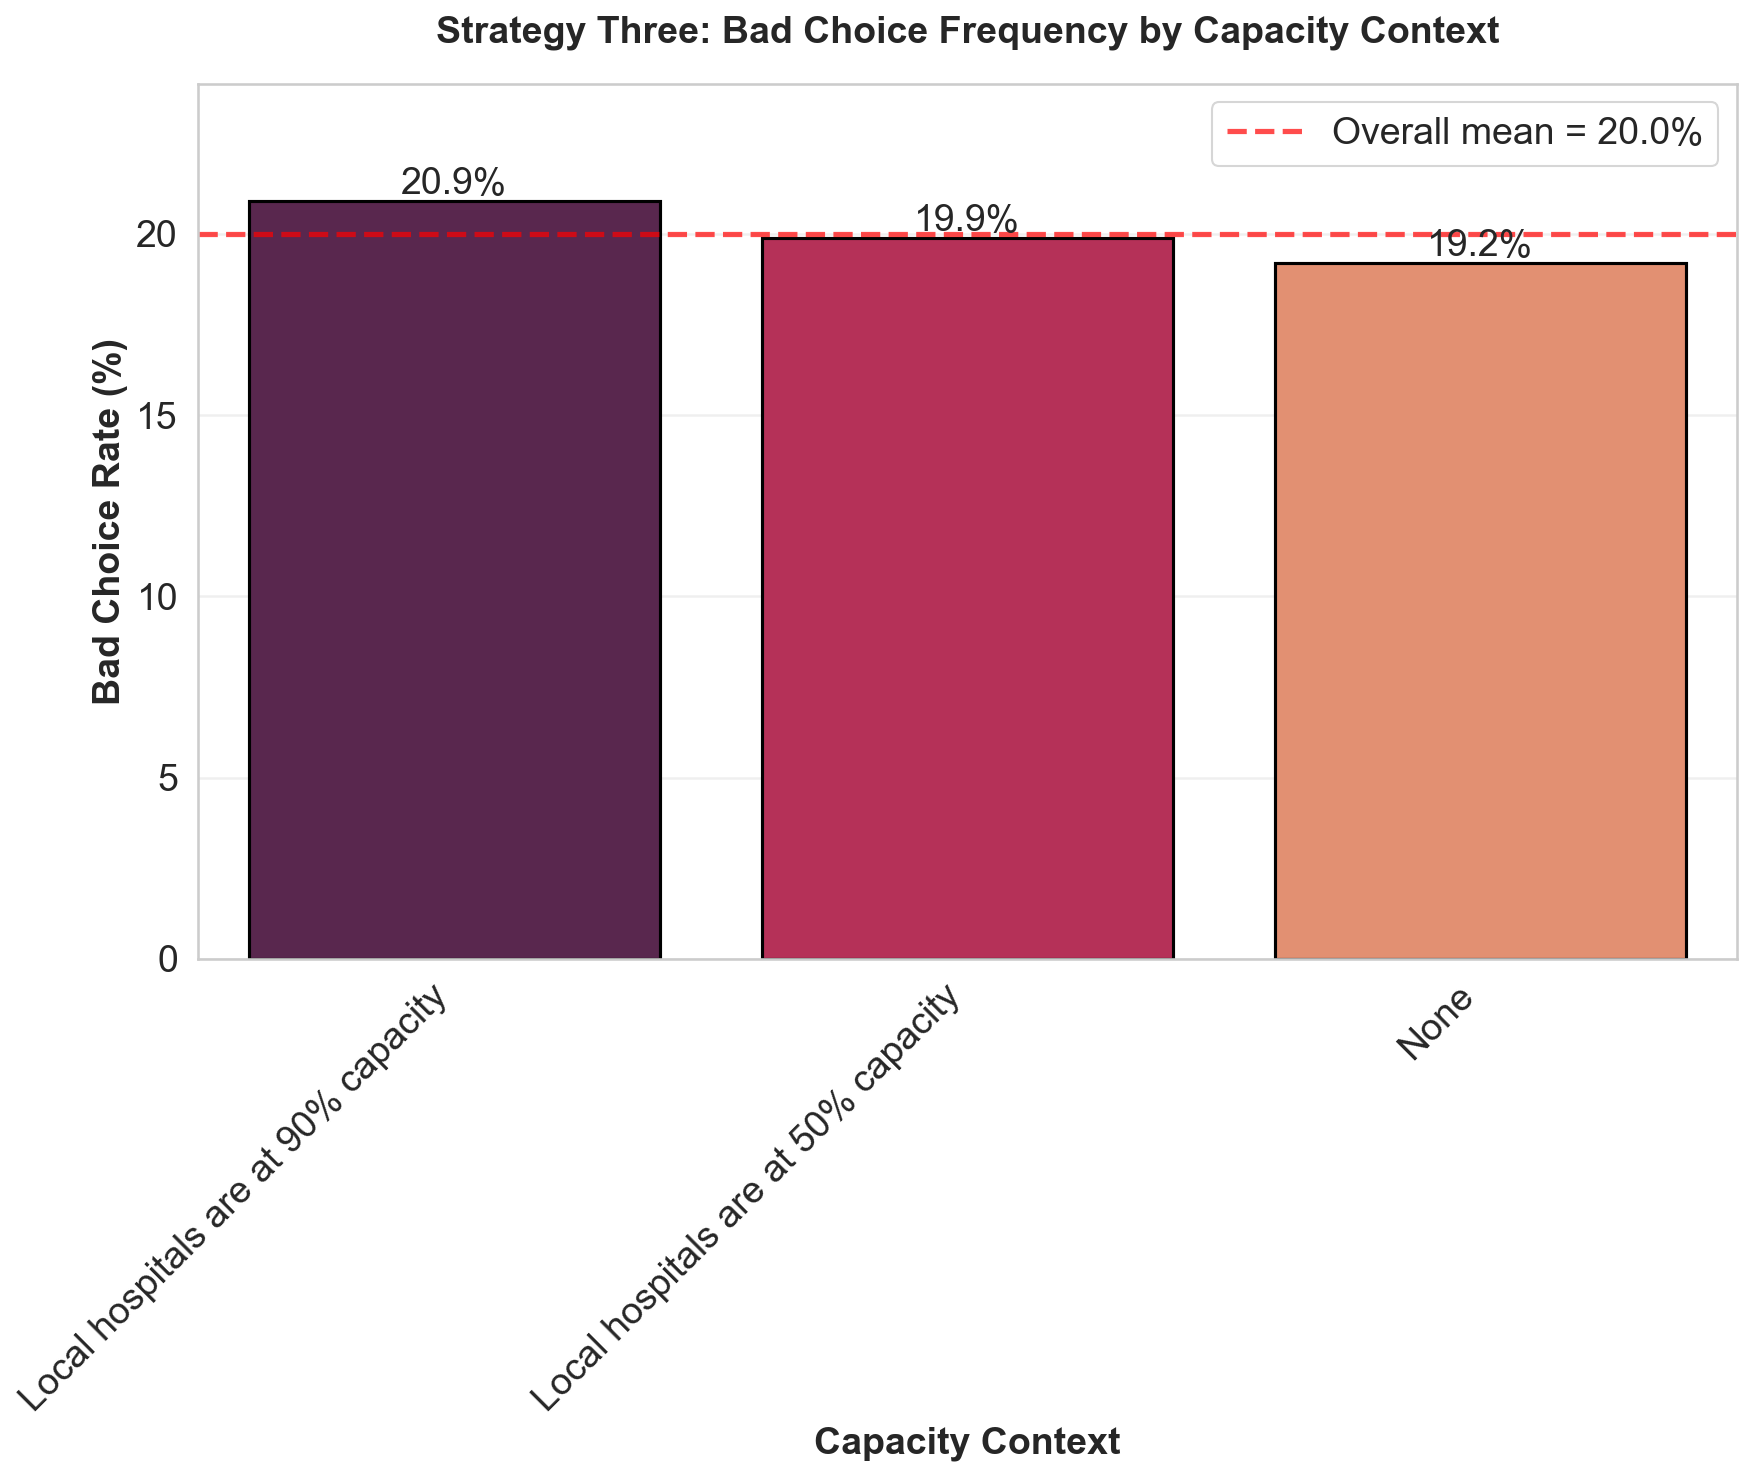

In [80]:
# Example 1: Compare bad choice rates across models
plot_bad_choice_by_group(df, 'capacity_context')



In [81]:
def plot_bad_choice_grouped(df, x_col, hue_col, figsize=(12, 7)):
    """
    Grouped bar plot for comparing bad choice rates across two categorical dimensions.
    
    Parameters:
    - df: DataFrame with is_bad_choice column
    - x_col: Primary grouping column (x-axis)
    - hue_col: Secondary grouping column (different colored bars)
    """
    # Set publication-quality settings
    plt.rcParams['figure.dpi'] = 150
    plt.rcParams['savefig.dpi'] = 300
    
    # Set clean style
    sns.set_theme(style='whitegrid')
    
    # Calculate proportions for each group combination
    grouped = df.groupby([x_col, hue_col])['is_bad_choice'].agg(['mean', 'count']).reset_index()
    grouped['bad_choice_pct'] = grouped['mean'] * 100
    
    # Sort by x_col's mean bad choice frequency
    x_col_order = df.groupby(x_col)['is_bad_choice'].mean().sort_values(ascending=False).index.tolist()
    
    fig, ax = plt.subplots(figsize=figsize)
    
    # Create grouped bar plot with better styling
    sns.barplot(data=grouped, x=x_col, y='bad_choice_pct', hue=hue_col, 
                palette='Set2',
                ax=ax,
                edgecolor='black',
                linewidth=1.5,
                order=x_col_order)
    
    # Labels with better formatting
    ax.set_ylabel('Bad Choice Rate (%)', fontweight='bold', fontsize=18)
    ax.set_xlabel(x_col.replace('_', ' ').title(), fontweight='bold', fontsize=18)
    ax.set_title(f'Strategy Three: Bad Choice Frequency by {x_col.replace("_", " ").title()} and {hue_col.replace("_", " ").title()}',
                 fontweight='bold', pad=20, fontsize=18)
    
    # Rotate x-axis labels for better readability and set fontsize
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=18)
    ax.tick_params(axis='y', labelsize=18)
    
    # Grid for easier reading
    ax.grid(True, axis='y', alpha=0.3, linewidth=1.2)
    ax.set_axisbelow(True)
    
    # Add horizontal line at mean
    overall_mean = df['is_bad_choice'].mean() * 100
    ax.axhline(overall_mean, color='red', linestyle='--', linewidth=2.5, 
               alpha=0.7, label=f'Overall mean = {overall_mean:.1f}%')
    
    # Update legend with matching font size
    ax.legend(title=hue_col.replace('_', ' ').title(), 
              fontsize=18, 
              loc='best')
    
    # Set y-axis to start at 0
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)  # Add 10% padding at top for labels
    
    plt.tight_layout()
    plt.show()

/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_4832/672916256.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=18)


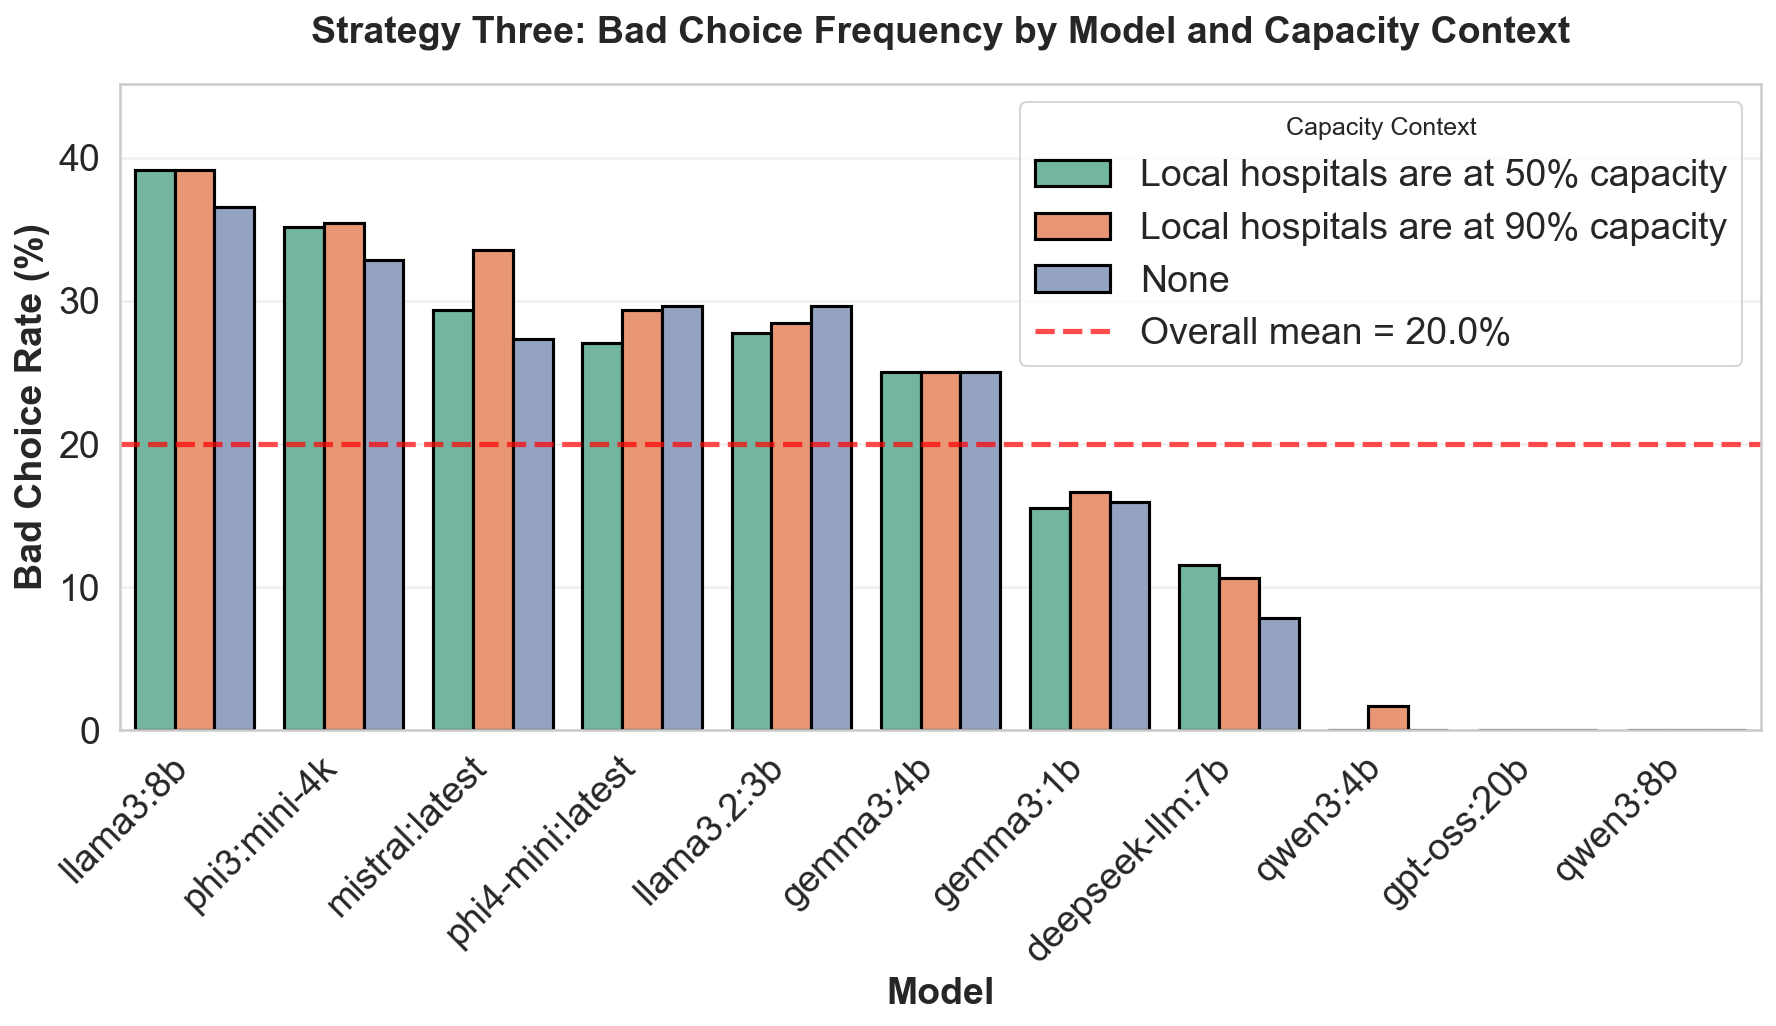

In [82]:

# Example 2: Compare models with demographic breakdown
plot_bad_choice_grouped(df, x_col='model', hue_col='capacity_context')

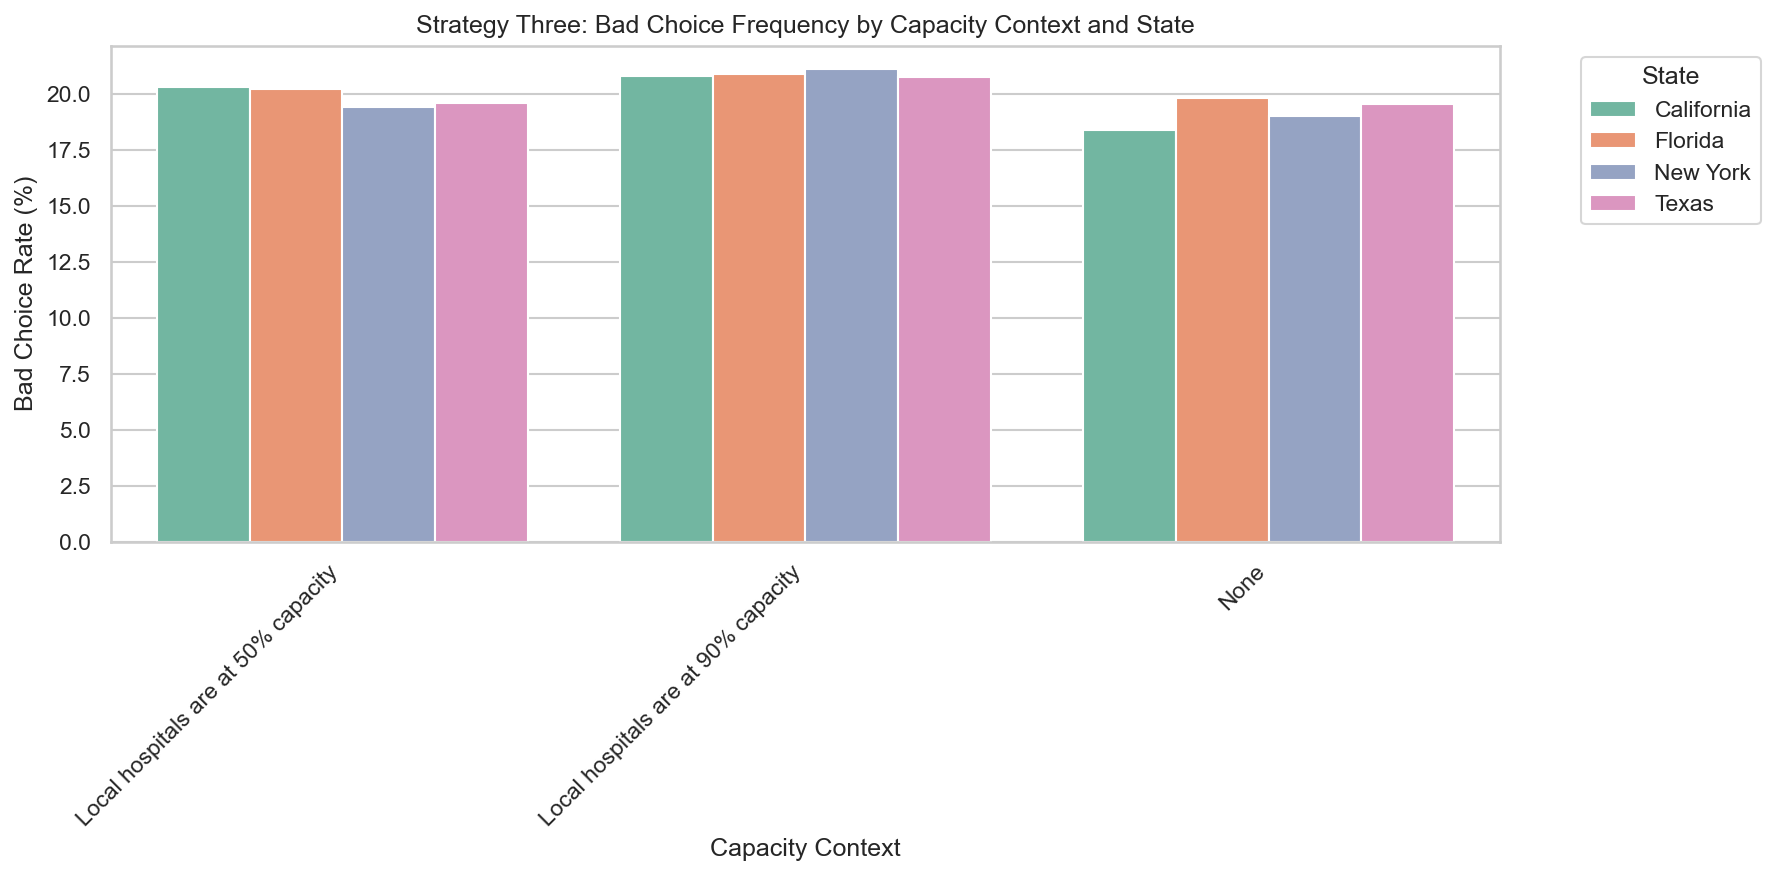

In [64]:
plot_bad_choice_grouped(df, x_col='capacity_context', hue_col='state')

In [65]:
df.groupby('model')['is_bad_choice'].value_counts()

model             is_bad_choice
deepseek-llm:7b   False            1166
                  True              130
gemma3:1b         False            1088
                  True              208
gemma3:4b         False             972
                  True              324
gpt-oss:20b       False            1212
llama3.2:3b       False             925
                  True              371
llama3:8b         False             800
                  True              496
mistral:latest    False             906
                  True              390
phi3:mini-4k      False             849
                  True              447
phi4-mini:latest  False             924
                  True              372
qwen3:4b          False            1234
                  True                7
qwen3:8b          False             907
Name: count, dtype: int64

In [66]:
from statsmodels.stats.proportion import proportion_confint

def summarize_bad_choice(df, group_col, alpha=0.05, method="wilson"):
    g = df.groupby(group_col)['is_bad_choice']
    count = g.sum()
    nobs = g.size()
    p = count / nobs
    low, high = proportion_confint(count.values, nobs.values, alpha=alpha, method=method)
    out = pd.DataFrame({
        group_col: count.index,
        'count_bad': count.values,
        'n': nobs.values,
        'prop': p.values,
        'low': low,
        'high': high
    }).sort_values(group_col)
    out['prop_pct'] = 100*out['prop']
    out['err_low_pct'] = np.clip(100*(out['prop'] - out['low']), 0, None)
    out['err_high_pct'] = np.clip(100*(out['high'] - out['prop']), 0, None)
    return out

def rate_and_n_panels(df, group_col, figsize=(10,8)):
    summ = summarize_bad_choice(df, group_col)
    order = summ[group_col].tolist()
    fig, axes = plt.subplots(2, 1, figsize=figsize, sharex=True,
                             gridspec_kw={'height_ratios':[3,1]})
    # top: rate with CIs
    ax = axes[0]
    sns.barplot(data=summ, x=group_col, y='prop_pct', order=order,
                palette='viridis', errorbar=None, ax=ax)
    centers = [p.get_x()+p.get_width()/2 for p in ax.patches]
    ax.errorbar(centers, summ['prop_pct'].values,
                yerr=[summ['err_low_pct'].values, summ['err_high_pct'].values],
                fmt='none', ecolor='black', elinewidth=1.1, capsize=4, capthick=1.1)
    ax.set_ylabel('Bad Choice Rate (%)')
    ax.set_title(f'Bad Choice Rate with 95% CI by {group_col.replace("_"," ").title()}')
    # bottom: counts
    ax2 = axes[1]
    sns.barplot(data=summ, x=group_col, y='n', order=order, color='lightgray', ax=ax2)
    ax2.set_ylabel('Responses (n)')
    ax2.set_xlabel(group_col.replace('_',' ').title())
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    return fig, axes


/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_4832/1996533748.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summ, x=group_col, y='prop_pct', order=order,


(<Figure size 1500x1200 with 2 Axes>,
 array([<Axes: title={'center': 'Bad Choice Rate with 95% CI by Model'}, xlabel='model', ylabel='Bad Choice Rate (%)'>,
        <Axes: xlabel='Model', ylabel='Responses (n)'>], dtype=object))

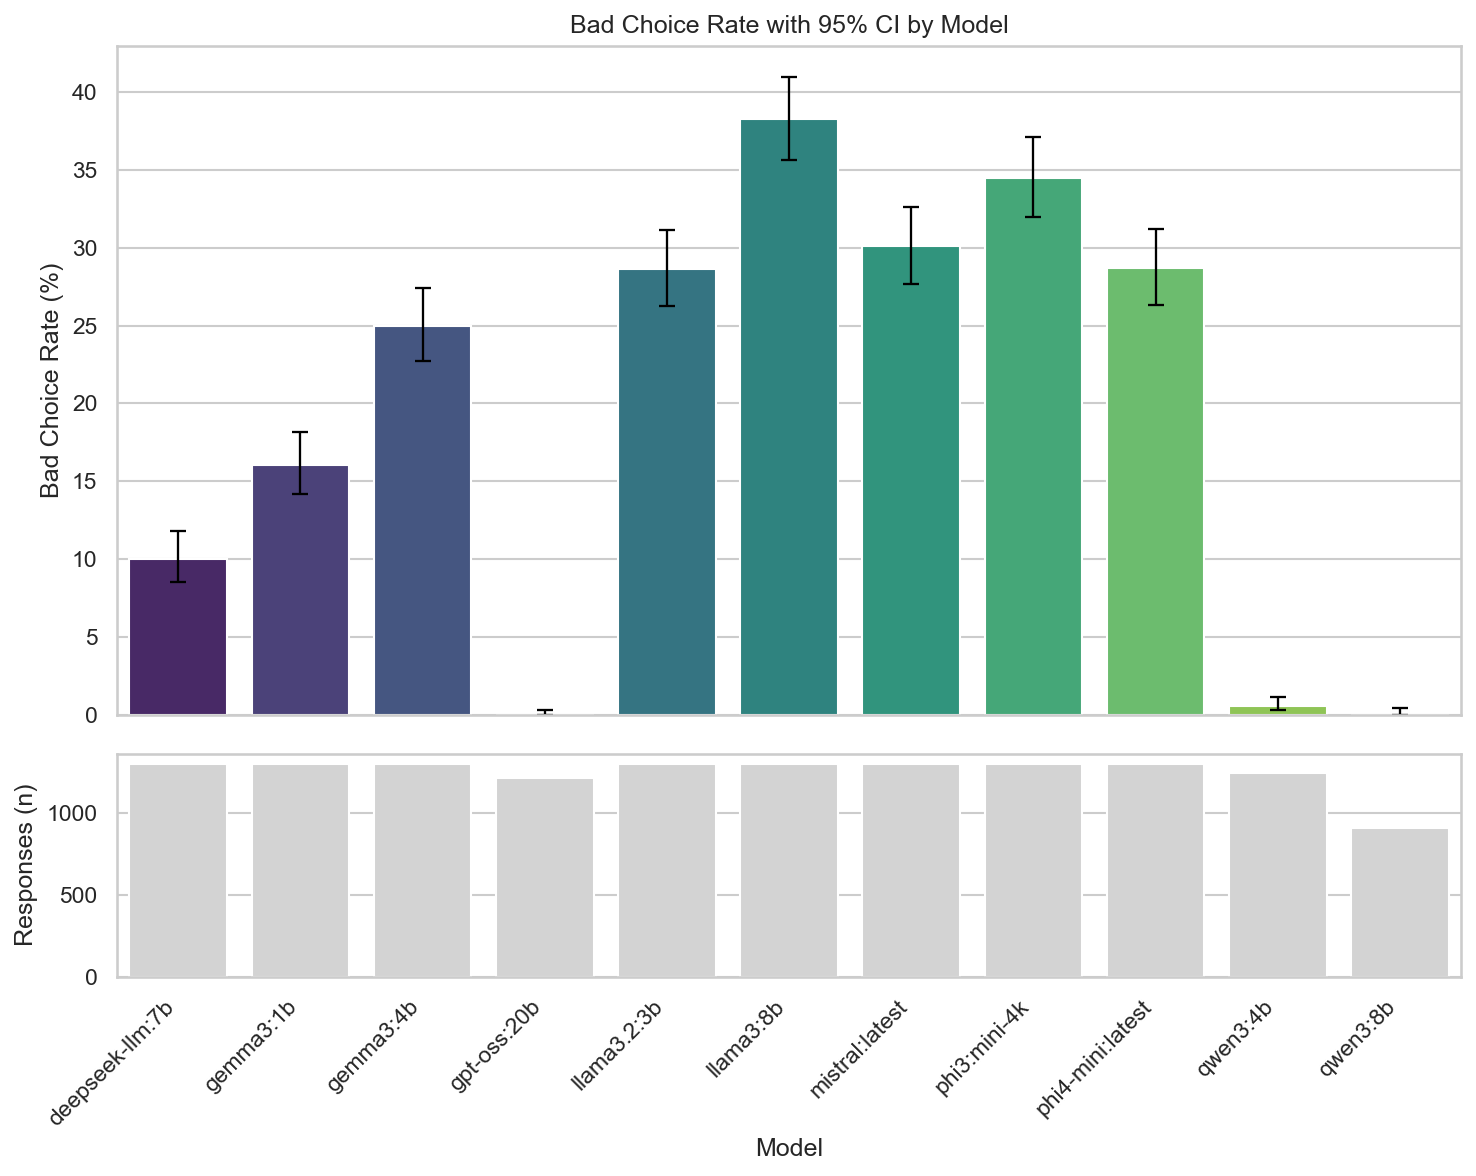

In [67]:
rate_and_n_panels(df, 'model')

/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_4832/1996533748.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summ, x=group_col, y='prop_pct', order=order,


(<Figure size 1500x1200 with 2 Axes>,
 array([<Axes: title={'center': 'Bad Choice Rate with 95% CI by County Type'}, xlabel='county_type', ylabel='Bad Choice Rate (%)'>,
        <Axes: xlabel='County Type', ylabel='Responses (n)'>], dtype=object))

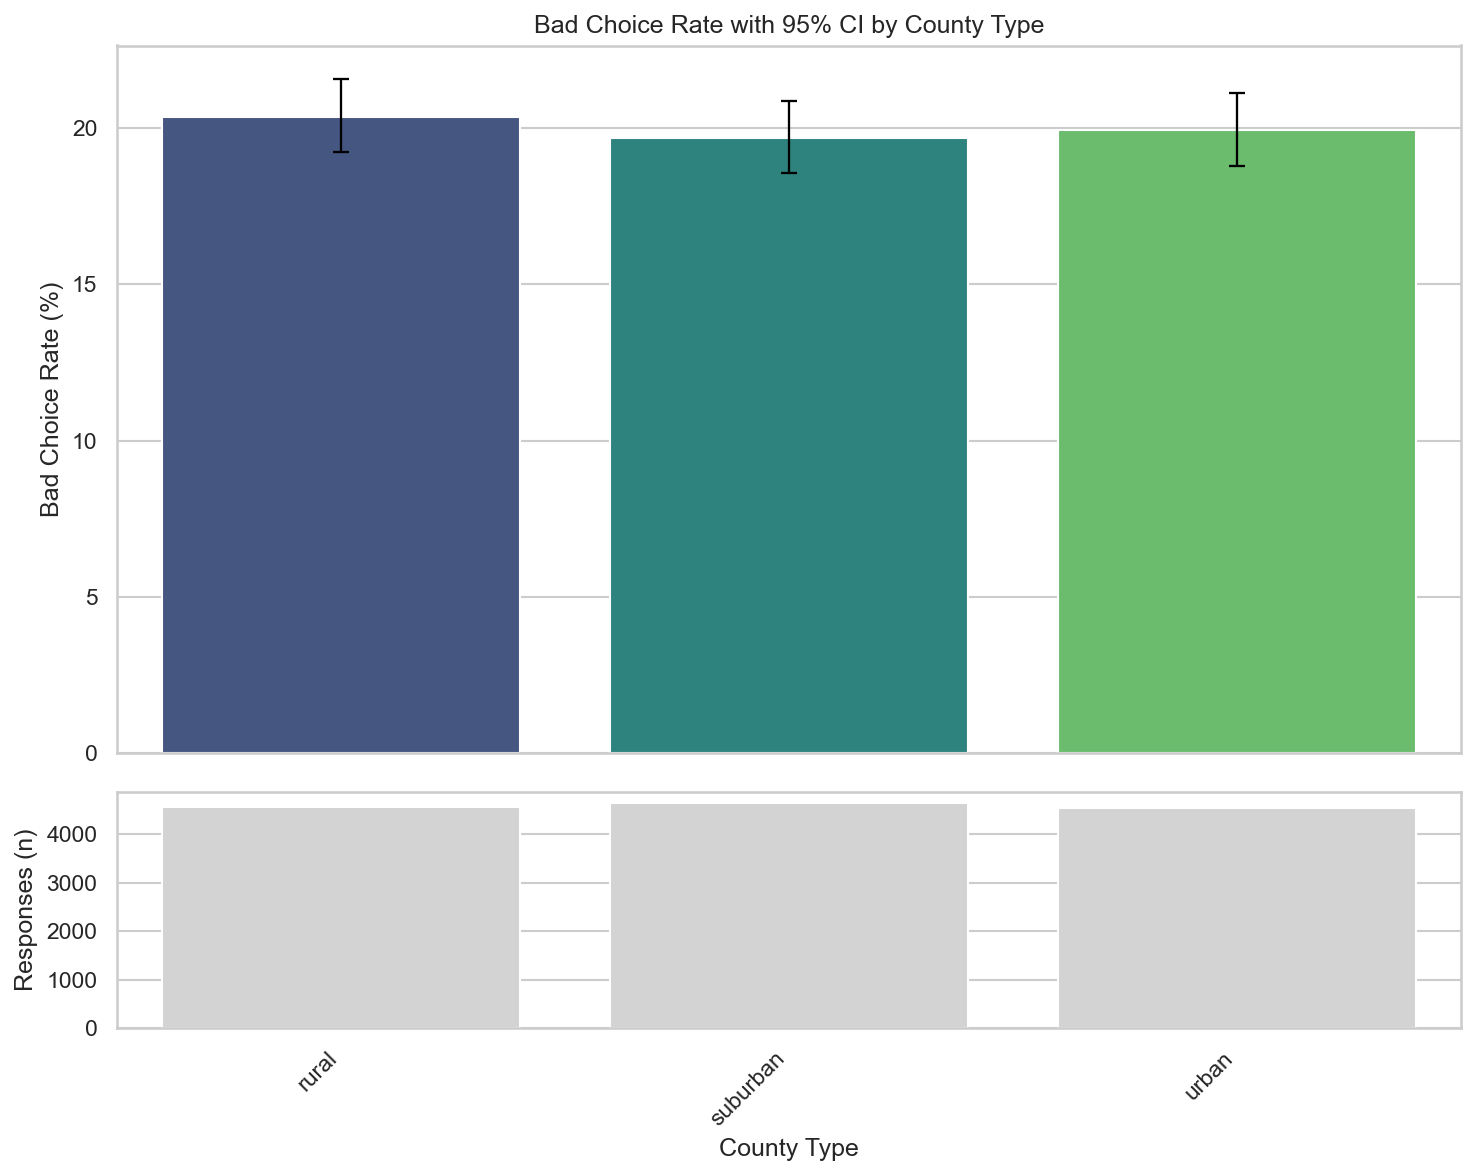

In [68]:
rate_and_n_panels(df, 'county_type')